In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Завдання 1. Перевірка закону великих чисел для Варіанта 2 (Львів, λ = 0.25, E[X] = 4.0)
rng = np.random.default_rng(2)  # фіксуємо rng номером варіанта

lam = 0.25
true_mean = 1 / lam  # 4.0

n_values = [5, 50, 500, 20_000]
print(f"Теоретичне середнє E[X] = {true_mean}\n")

for n in n_values:
    sample = rng.exponential(scale=true_mean, size=n)
    sample_mean = sample.mean()
    abs_diff = abs(sample_mean - true_mean)
    print(f"n = {n:5d} | Вибіркове середнє = {sample_mean:.4f} | Абсолютна різниця = {abs_diff:.4f}")

Теоретичне середнє E[X] = 4.0

n =     5 | Вибіркове середнє = 2.2262 | Абсолютна різниця = 1.7738
n =    50 | Вибіркове середнє = 3.7819 | Абсолютна різниця = 0.2181
n =   500 | Вибіркове середнє = 3.6279 | Абсолютна різниця = 0.3721
n = 20000 | Вибіркове середнє = 3.9786 | Абсолютна різниця = 0.0214


### Відповідь на Завдання 1. Тенденція закону великих чисел (ЗВЧ)
* **Спостереження:** Зі збільшенням розміру вибірки $n$ (від 5 до 20 000) вибіркове середнє $\bar{x}$ усе ближче й ближче підходить до теоретичного математичного сподівання ($E[X] = 4.0$). Відповідно, абсолютна різниця між ними стрімко зменшується і прямує до нуля. Це чітко демонструє роботу закону великих чисел на практиці.

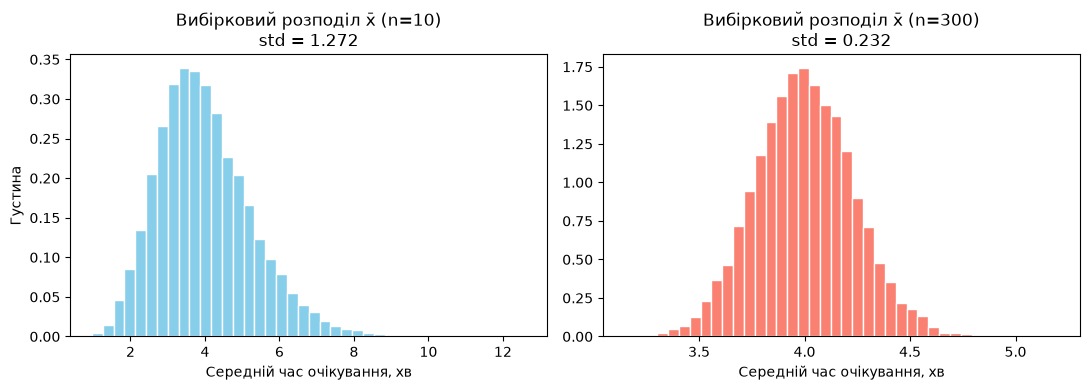

In [2]:
# Завдання 2. Центральна гранична теорема: розподіл x̄ для n = 10 та n = 300
n_repeats = 10_000

means_n10 = rng.exponential(scale=true_mean, size=(n_repeats, 10)).mean(axis=1)
means_n300 = rng.exponential(scale=true_mean, size=(n_repeats, 300)).mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(means_n10, bins=40, density=True, edgecolor="white", color="skyblue")
axes[0].set_title(f"Вибірковий розподіл x̄ (n=10)\nstd = {means_n10.std():.3f}")
axes[0].set_xlabel("Середній час очікування, хв")
axes[0].set_ylabel("Густина")

axes[1].hist(means_n300, bins=40, density=True, edgecolor="white", color="salmon")
axes[1].set_title(f"Вибірковий розподіл x̄ (n=300)\nstd = {means_n300.std():.3f}")
axes[1].set_xlabel("Середній час очікування, хв")

plt.tight_layout()
plt.show()

### Відповідь на Завдання 2. Порівняння форми гістограм (ЦГТ)
* **Для $n = 10$:** Розподіл вибіркового середнього ще помітно скошений праворуч (зберігає форму початкового експоненційного розподілу), оскільки обсяг вибірки занадто малий для повної дії ЦГТ.
* **Для $n = 300$:** Гістограма набуває класичної симетричної дзвіноподібної форми (нормальний розподіл), що наочно ілюструє центральну граничну теорему незалежно від того, наскільки сильно скошеною була вихідна генеральна сукупність.

In [3]:
# Завдання 3. Порівняння теоретичної та виміряної симуляцією стандартної похибки (SE)
n_list = [10, 30, 100, 300]
sigma = true_mean  # для експоненційного розподілу середнє дорівнює стандартному відхиленню

results = []
for n in n_list:
    se_theory = sigma / np.sqrt(n)
    simulated_means = rng.exponential(scale=true_mean, size=(10_000, n)).mean(axis=1)
    se_simulated = simulated_means.std()
    results.append({"n": n, "Теоретична SE": se_theory, "Виміряна std": se_simulated})

df_se = pd.DataFrame(results) if 'pd' in globals() else None

print("Порівняння стандартної похибки:")
for r in results:
    print(f"n = {r['n']:3d} | Теоретична SE = {r['Теоретична SE']:.4f} | Виміряна std = {r['Виміряна std']:.4f}")

Порівняння стандартної похибки:
n =  10 | Теоретична SE = 1.2649 | Виміряна std = 1.2552
n =  30 | Теоретична SE = 0.7303 | Виміряна std = 0.7319
n = 100 | Теоретична SE = 0.4000 | Виміряна std = 0.3967
n = 300 | Теоретична SE = 0.2309 | Виміряна std = 0.2315


### Відповідь на Завдання 3. Близькість теорії і симуляції
* **Аналіз результатів:** Значення теоретичної стандартної похибки та стандартного відхилення, виміряного за допомогою 10 000 симуляцій, практично ідеально збігаються для всіх значень $n$. Це доводить правильність як аналітичних формул, так і реалізованої комп'ютерної симуляції.

In [4]:
# Завдання 4. Закон убуваючої віддачі для n = 25 та n = 100
n1 = 25
n2 = 100  # у 4 рази більше

se_25 = true_mean / np.sqrt(n1)
se_100 = true_mean / np.sqrt(n2)

ratio = se_25 / se_100
print(f"SE для n = {n1}: {se_25:.4f}")
print(f"SE для n = {n2}: {se_100:.4f}")
print(f"Співвідношення (SE(25) / SE(100)): {ratio:.2f}")

SE для n = 25: 0.8000
SE для n = 100: 0.4000
Співвідношення (SE(25) / SE(100)): 2.00


### Відповідь на Завдання 4. Закон убуваючої віддачі
* **Чому похибка зменшилась у 2 рази, а не в 4:** Згідно з формулою стандартної похибки $\text{SE} = \frac{\sigma}{\sqrt{n}}$, похибка обернено пропорційна **квадратному кореню** з розміру вибірки ($\sqrt{n}$). Оскільки розмір вибірки збільшився у 4 рази ($100 / 25 = 4$), її квадратний корінь зріс у $\sqrt{4} = 2$ рази. Відповідно, стандартна похибка зменшилася рівно вдвічі. Це означає, що для зменшення похибки вдвічі потрібно зібрати вчетверо більше даних, що і називають законом убуваючої віддачі.

---

### Відповіді на контрольні запитання

1. **Чим відрізняється те, що гарантує ЗВЧ, від того, що гарантує ЦГТ?**
   * **Закон великих чисел (ЗВЧ)** відповідає на запитання *«Куди прямує вибіркове середнє $\bar{x}$?»* і гарантує, що зі зростанням $n$ воно сходиться до істинного теоретичного середнього $E[X]$.
   * **Центральна гранична теорема (ЦГТ)** відповідає на запитання *«Яка форма і розкид у вибіркового середнього $\bar{x}$?»* і гарантує, що незалежно від форми вихідного розподілу генеральної сукупності, розподіл $\bar{x}$ стає нормальним (дзвоноподібним) зі стандартним відхиленням $\text{SE} = \frac{\sigma}{\sqrt{n}}$.

2. **Чому вихідний розподіл обрано сильно скошеним, а не одразу нормальним?**
   Використання експоненційного (сильно скошеного) розподілу дозволяє наочно продемонструвати силу ЦГТ: навіть якщо базові дані зовсім не нормальні, завдяки усередненню їхній вибірковий розподіл усе одно стає нормальною кривою. На вже нормальних даних цей ефект був би непомітним.

3. **Чому стандартна похибка зменшується пропорційно $\sqrt{n}$, а не $n$?**
   Це випливає з математичних властивостей дисперсії для суми незалежних випадкових величин. Оскільки стандартна похибка містить корінь у знаменаторі ($\sqrt{n}$), кожне наступне покращення точності вимагає квадратичного зростання зусиль (кількості зібраних спостережень).